##**1. Objective**

The aim of this part is to remove a sinusoidal interference tone from a speech recording. In Part 3 a tone at 60 Hz was added to the clean audio, producing noisy.wav. In this part a second-order IIR notch filter is designed, its coefficients are calculated for the interference frequency, the noisy audio is filtered, and the result is saved as filtered.wav.

##**2. Listening test**

The files noisy.wav and filtered.wav were played. In the noisy file a steady low-pitched hum at 60 Hz is clearly audible throughout the recording. In the filtered file the hum is removed and the speech remains clear and natural.

##**3. Theory**

##**3.1 Digital filters**

A digital filter is a discrete-time LTI system that modifies the frequency content of a signal. It is described by the difference equation and by its transfer function

H(z) = B(z) / A(z)

where B(z) holds the feed-forward (numerator) coefficients and A(z) the feedback (denominator) coefficients. Evaluating H(z) on the unit circle, z = e^{jω}, gives the frequency response.

##**3.2 FIR (Finite Impulse Respons) and IIR (Infinite Impulse Respons) filters**

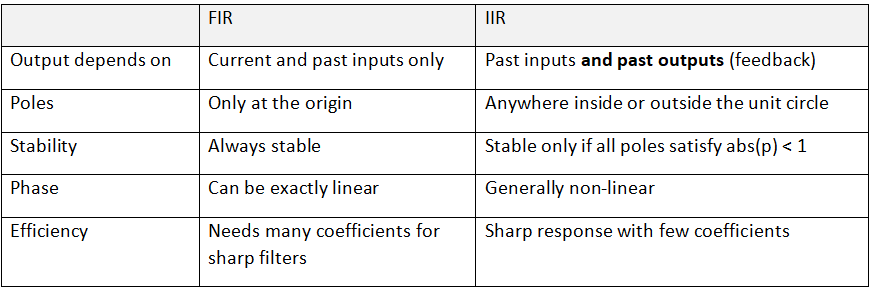

The notch filter used here is IIR, because its denominator has non-trivial coefficients (a1, a2 ≠ 0). Feedback lets it produce a very narrow notch with only five coefficients.

##**3.3 Zeros and poles**

Zeros are the roots of the numerator: the gain is zero when the frequency lies on a zero. Poles are the roots of the denominator: the gain rises when the frequency approaches a pole. A notch filter places a pair of zeros on the unit circle at the unwanted frequency, which gives exactly zero gain there, and a pair of poles at the same angle but slightly inside the circle, at radius r. The poles cancel the effect of the zeros everywhere except very close to the notch, so the gain returns to about 1 (0 dB) at all other frequencies.

##**3.4 Stability**

A causal discrete-time system is stable (bounded input bounded output) if and only if all poles lie strictly inside the unit circle. For this filter the poles have magnitude r, so stability requires 0 < r < 1.

##**4. Filter Design**

The second-order notch has the transfer function

H(z) = K · (1 − 2cos(ω0) z^-1 + z^-2) / (1 − 2r cos(ω0) z^-1 + r² z^-2)

where

•ω0 = 2π f0 / fs is the normalized notch frequency (rad/sample),

•r is the pole radius (closer to 1 gives a narrower notch),

•K is a gain constant.

Zeros: z = e^{±jω0} (on the unit circle). Poles: z = r e^{±jω0}.

##**4.1 Coefficients**

b0 = K, b1 = −2K cos(ω0), b2 = K and a0 = 1, a1 = −2r cos(ω0), a2 = r².

The constant K is chosen so that the gain at Nyquist (z = −1) equals 1 (0 dB):

K = (1 + 2r cos(ω0) + r²) / (2 + 2cos(ω0))

//In the code, this is computed as K = (a0 − a1 + a2)/(b0 − b1 + b2), which is the same expression evaluated at z = −1 and H(z)=1

##**4.2 Calculated values**

The selected pole radius is r = 0.999.

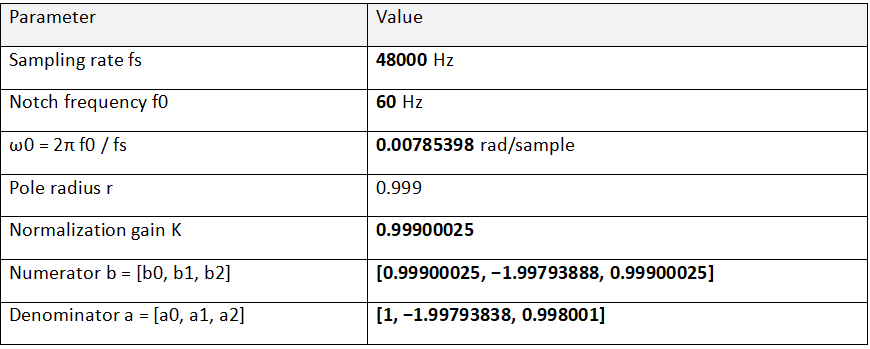

##**Quantitative result**

##**4.3 Effect of the pole radius**

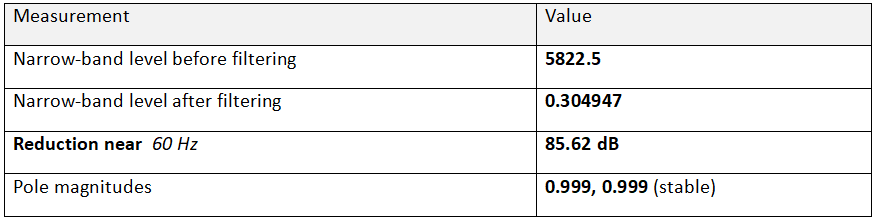

The bandwidth of the notch is approximately

BW ≈ (1 − r) · fs / π

For r = 0.999 and fs = 48000 Hz this gives a bandwidth of about 15.3 Hz.

A larger r makes the notch narrower, so less of the speech around  60 Hz is
removed, but the filter takes longer to settle (longer ringing).

A smaller r widens the notch, so more speech energy near  60 Hz is attenuated, but
the transient dies out faster.

##**5. Implementation**

The filter was implemented in Python with NumPy, SciPy and Matplotlib.

1.The noisy WAV file is read and its integer samples are converted to floating
point in the range [−1, 1].

2.The coefficients b and a are calculated from f0, fs and r using the equations in Section 4.

3.The filter is applied with scipy.signal.lfilter. Stereo files are filtered channel by channel.

4.A short fade-in and fade-out (30 ms) is applied to start and ends of the output to avoid audible clicks at the file boundaries. This is optional post-processing and is not part of the notch filter itself.

5.The result is clipped to [−1, 1] and saved as a 32-bit floating-point WAV file (filtered.wav).

6.The interference reduction is measured and the comparison figures are generated.
The reduction is measured as the RMS of the Hann-windowed FFT magnitude in a narrow band of ±2 Hz around  60 Hz, before and after filtering, expressed in dB:
Reduction = 20 log10(level_before / level_after)

##**6. Results**

##**6.1 Time-domain comparison**

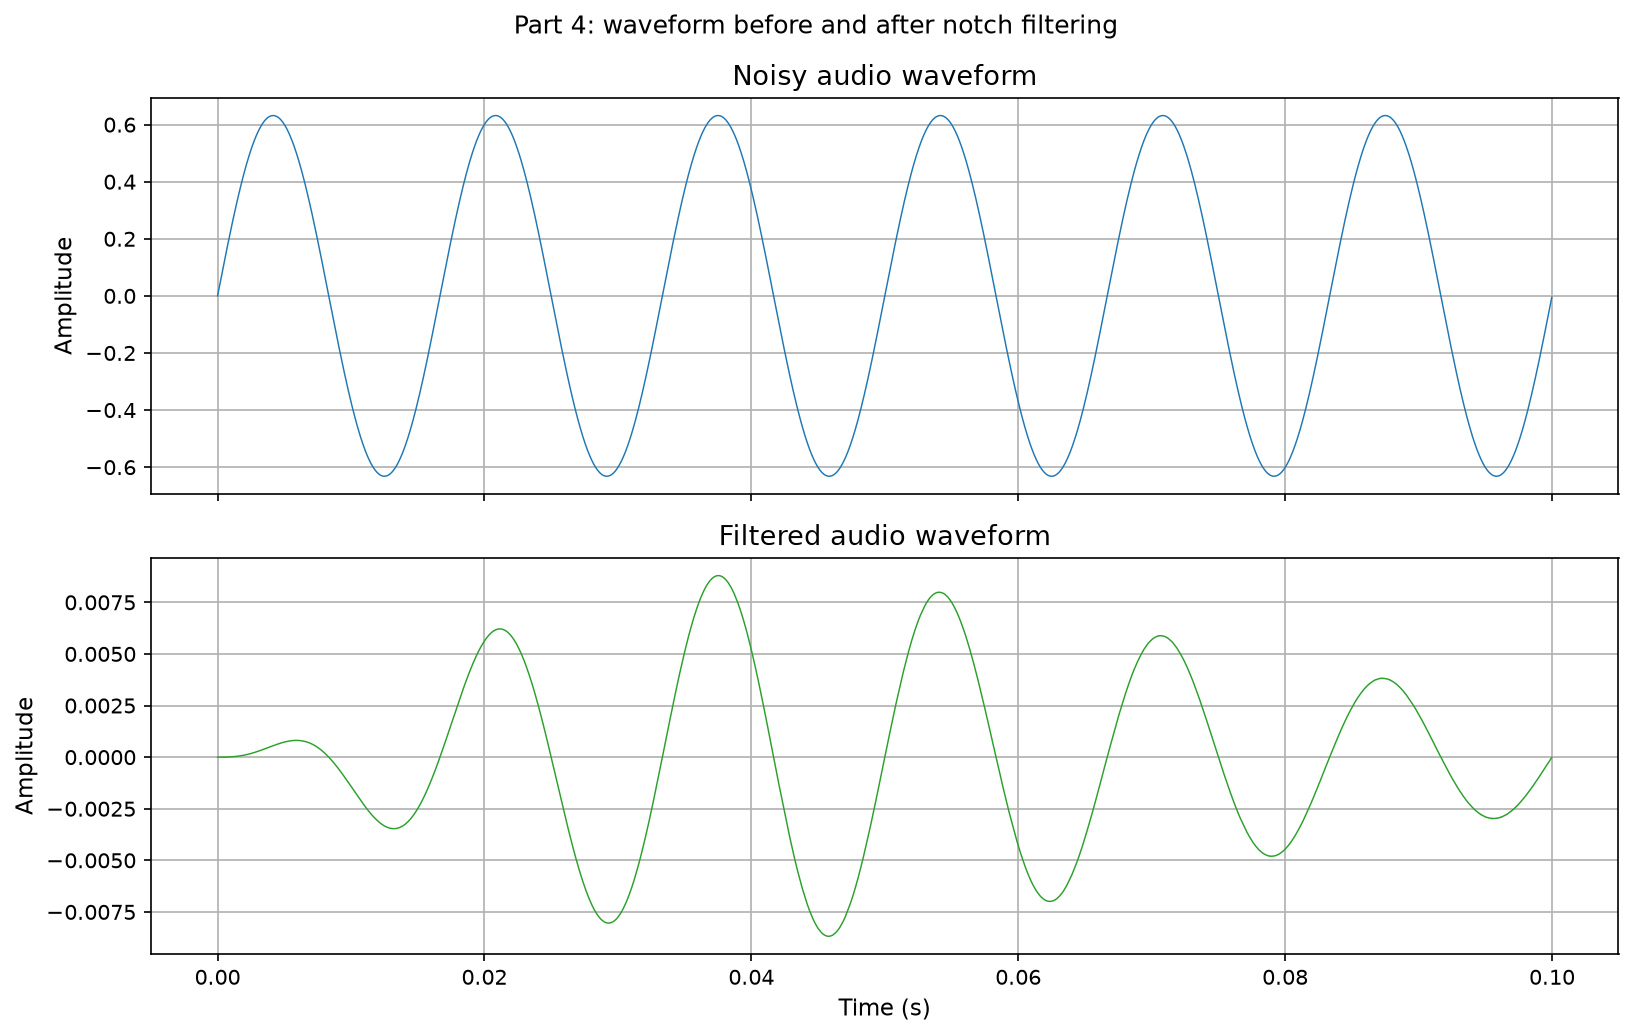

Figure 1: Waveform of the first 100 ms before and after notch filtering. The noisy signal is dominated by the steady 60 Hz tone (six cycles in 0.1 s, amplitude ≈ 0.63). The filtered signal starts from zero and shows a decaying oscillation at about the same frequency, which is the filter's transient response , Once the transient has died out, the 60 Hz tone is removed

##**6.2 Frequency-domain comparison**

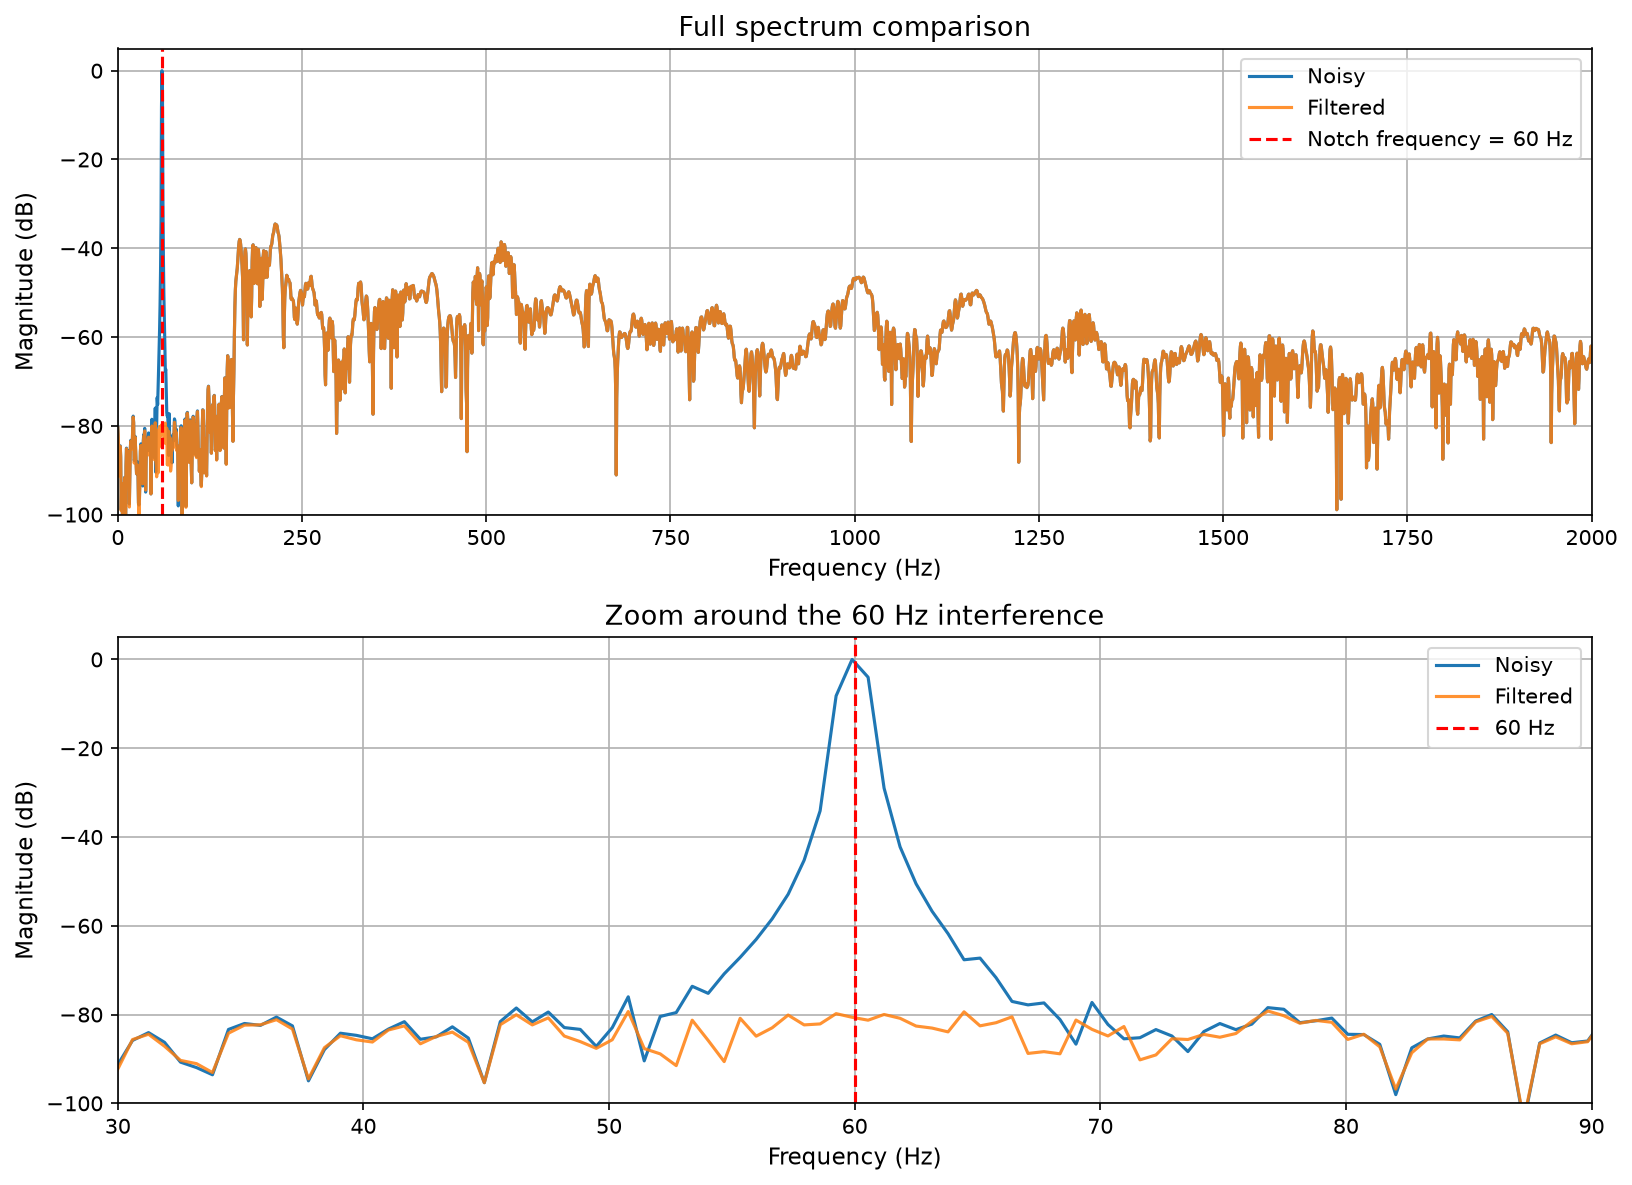

Figure 2: Magnitude spectrum before and after filtering, with a zoom around  60 Hz. The noisy spectrum shows a sharp peak at 60 Hz, well above the neighbouring speech spectrum. After filtering this peak is removed, while the rest of the spectrum remains essentially unchanged, which shows that the speech was preserved.

##**6.3 Filter frequency response**

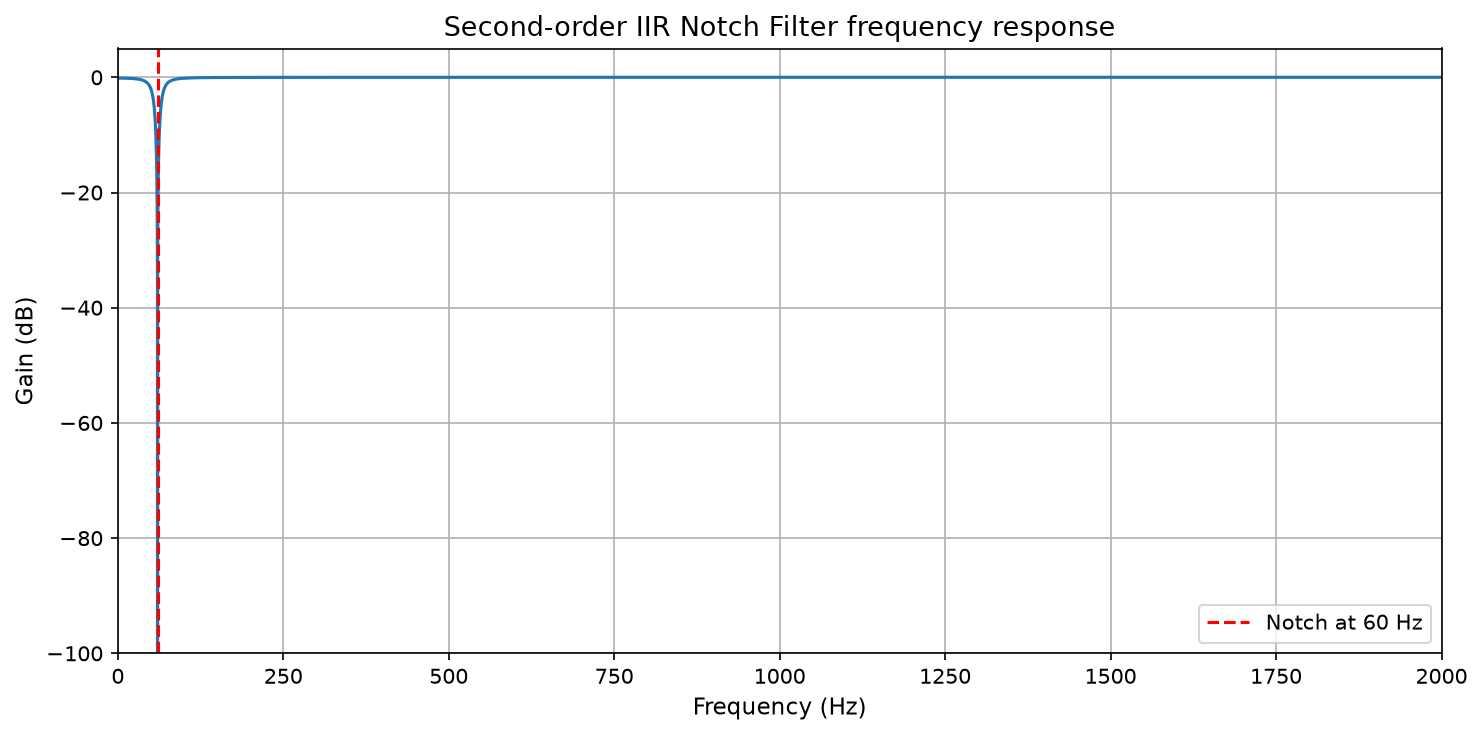

Figure 3: Magnitude response of the designed notch filter. The response drops sharply to a deep null at 60 Hz and stays at about 0 dB at all other frequencies. Because the notch is very narrow, it appears as a thin line on the 0–2000 Hz axis; its width is about 15 Hz (see Section 4.3).

##**6.4 Pole-zero plot and stability**

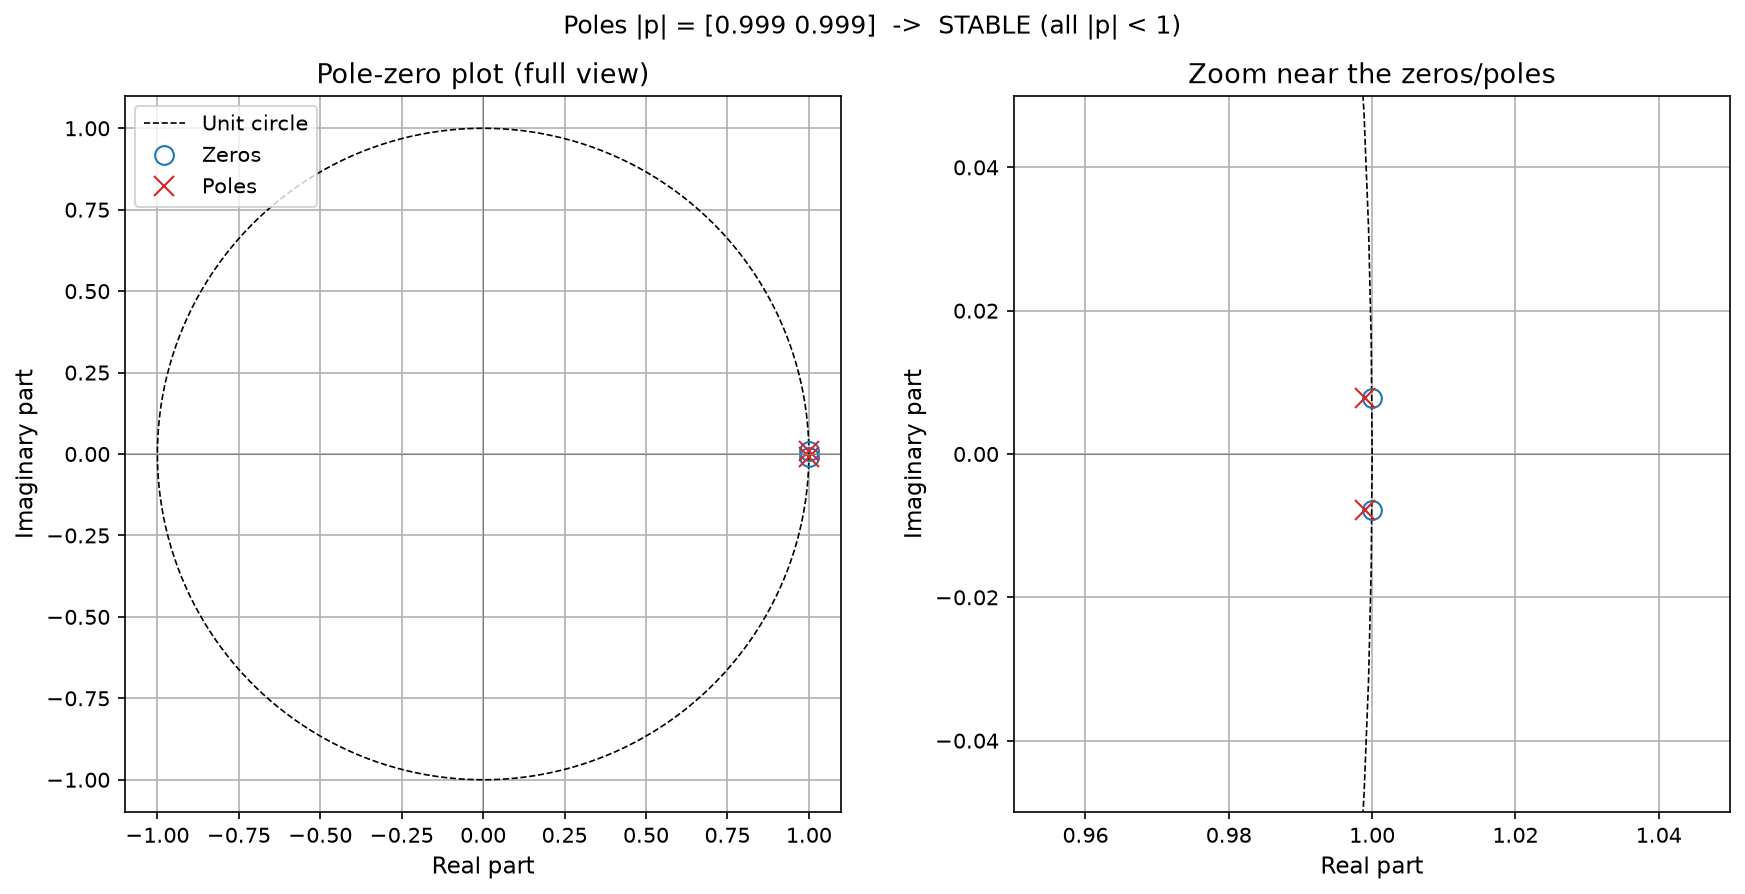

Figure 4: Pole-zero plot. The two zeros lie on the unit circle at angles ±ω0, and the two poles lie at the same angles with radius 0.999, just inside the circle. The computed zeros are 0.999969 ± 0.007854j and the poles 0.998969 ± 0.007846j. The pole magnitudes are 0.999 and 0.999, both less than 1, so the filter is stable.